In [12]:
# Learning and running through battery dataset and their characteristics from APMonitor
import numpy as np
import pandas as pd

from IPython.display import display, HTML
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.io as pio


import seaborn as sns
from importlib import reload
import matplotlib.pyplot as plt
import matplotlib
import warnings

# Configure Jupyter Notebook
pd.set_option('display.max_columns', None) 
pd.set_option('display.max_rows', 500) 
pd.set_option('display.expand_frame_repr', False)
display(HTML("<style>div.output_scroll { height: 35em; }</style>"))

reload(plt)
%matplotlib inline
%config InlineBackend.figure_format ='retina'

warnings.filterwarnings('ignore')

In [94]:
df = pd.read_csv("battery_data.csv")

In [14]:
df.head()

,Cycle_Index,Discharge Time (s),Decrement 3.6-3.4V (s),Max. Voltage Dischar. (V),Min. Voltage Charg. (V),Time at 4.15V (s),Time constant current (s),Charging time (s),RUL
0,1.0,2595.30,1151.488500,3.670,3.211,5460.001,6755.01,10777.82,1112
1,2.0,7408.64,1172.512500,4.246,3.220,5508.992,6762.02,10500.35,1111
2,3.0,7393.76,1112.992000,4.249,3.224,5508.993,6762.02,10420.38,1110
3,4.0,7385.50,1080.320667,4.250,3.225,5502.016,6762.02,10322.81,1109
4,6.0,65022.75,29813.487000,4.290,3.398,5480.992,53213.54,56699.65,1107


Adding Battery ID Column to identify batteries (expected of 14), done by checking the RUL value, once it is zero, it is then another new battery

In [15]:
df['Battery ID']= 0 
batteries=[] 
ID=1
for rul in df['RUL']: 
    batteries.append(ID) 
    if rul == 0: 
        ID+=1
        continue
df['Battery ID'] = batteries 

array([<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
       <Axes: >, <Axes: >, <Axes: >, <Axes: >], dtype=object)

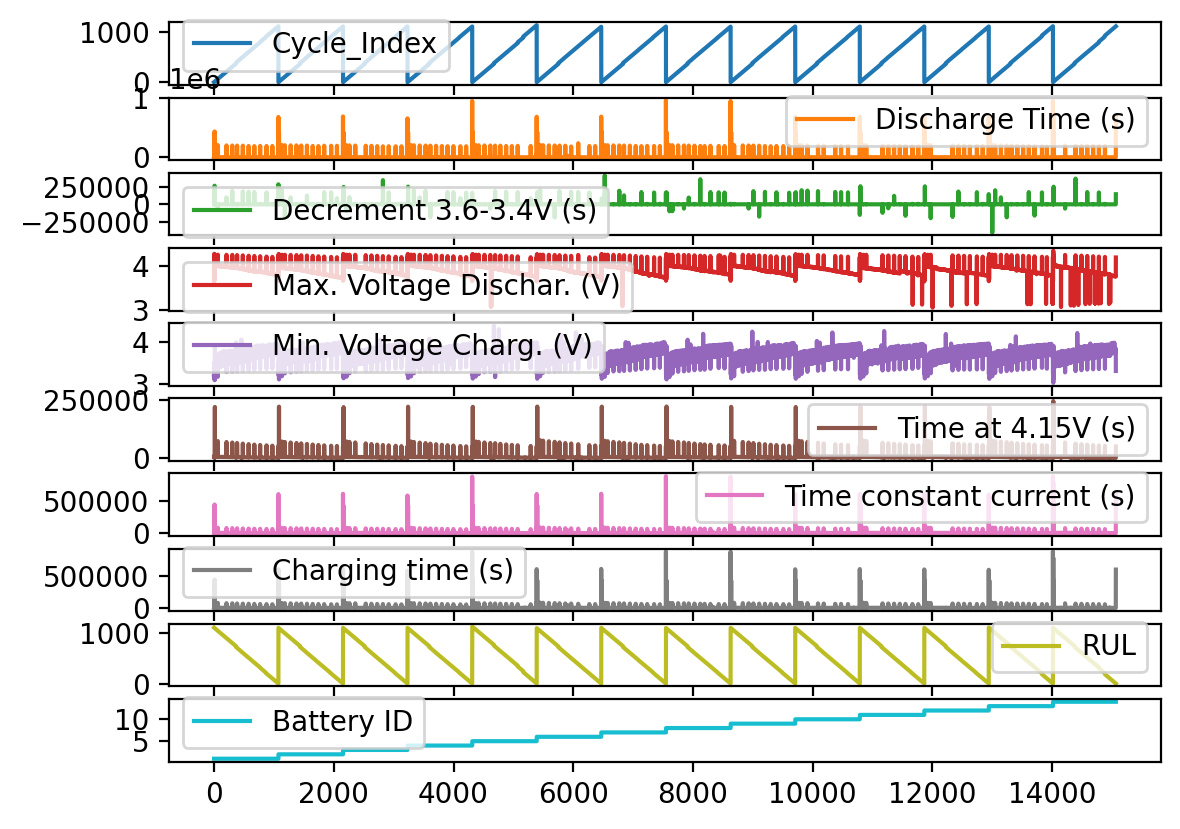

In [16]:
df.plot(subplots=True)

From domain knowledge, we should expect cycle during charge discharge cycle. We notice and can see that there are issue with the upper (and lower) value in which we set a threshold. The value of the following threshold were derived from the exisitng discussion and would be utilized.

In [96]:
df = df[(df['Discharge Time (s)']<2500) & (df['Discharge Time (s)']>500)]
df = df[(df['Max. Voltage Dischar. (V)']<4.1) & (df['Max. Voltage Dischar. (V)']>3.7)]
df = df[(df['Min. Voltage Charg. (V)']<4.05)]
df = df[(df['Time constant current (s)']<7000)]

array([<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
       <Axes: >, <Axes: >, <Axes: >, <Axes: >], dtype=object)

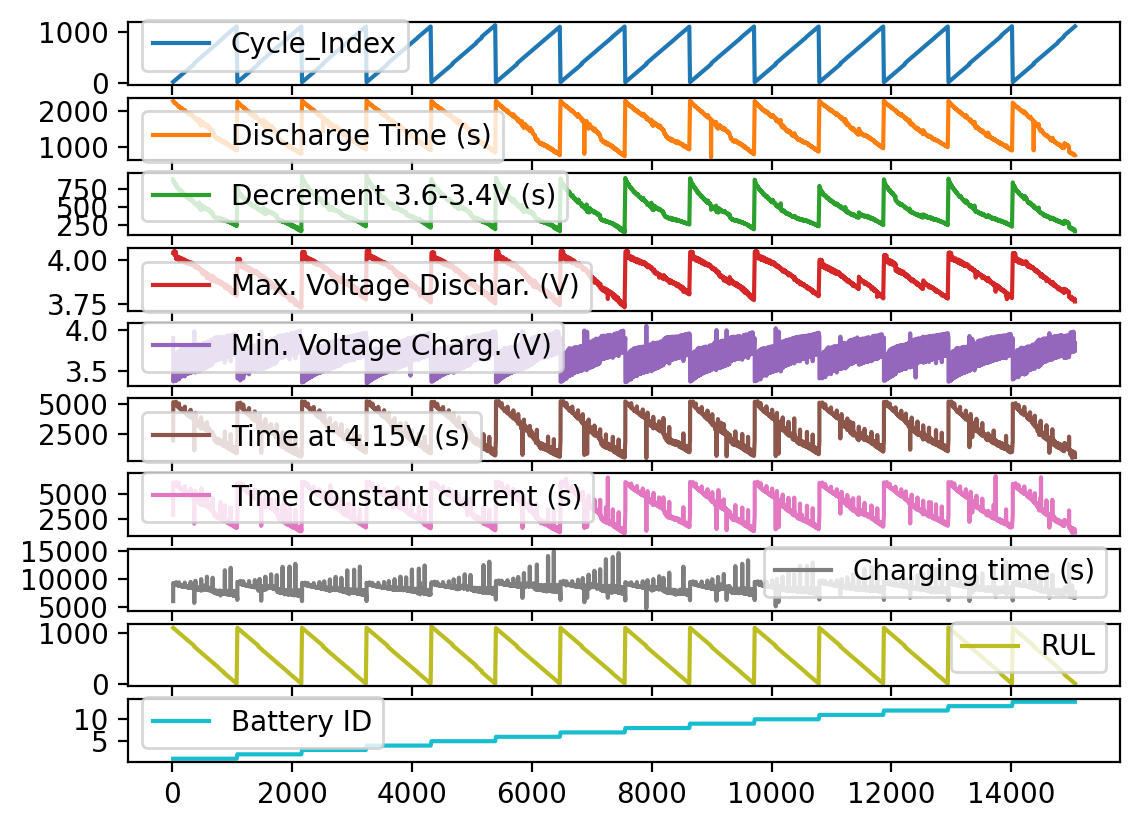

In [23]:
df.plot(subplots=True)

In the documentation, it is performed joint plot, pair plot and correlation map to detect features that might be useful to our target variable - redacted for brevity. More details can be found on their website.

In [8]:
train_battery_ids = []
test_battery_ids = []
battery_ids = df['Battery ID'].unique()

for i in battery_ids:
    if i<9:
        train_battery_ids.append(i)
    else:
        test_battery_ids.append(i)
df_train = df[df['Battery ID'].isin(train_battery_ids)]
df_test = df[df['Battery ID'].isin(test_battery_ids)]

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15064 entries, 0 to 15063
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Cycle_Index                15064 non-null  float64
 1   Discharge Time (s)         15064 non-null  float64
 2   Decrement 3.6-3.4V (s)     15064 non-null  float64
 3   Max. Voltage Dischar. (V)  15064 non-null  float64
 4   Min. Voltage Charg. (V)    15064 non-null  float64
 5   Time at 4.15V (s)          15064 non-null  float64
 6   Time constant current (s)  15064 non-null  float64
 7   Charging time (s)          15064 non-null  float64
 8   RUL                        15064 non-null  int64  
 9   Battery ID                 15064 non-null  int64  
dtypes: float64(8), int64(2)
memory usage: 1.1 MB


,Cycle_Index,Discharge Time (s),Decrement 3.6-3.4V (s),Max. Voltage Dischar. (V),Min. Voltage Charg. (V),Time at 4.15V (s),Time constant current (s),Charging time (s),RUL,Battery ID
0,1.0,2595.30,1151.488500,3.670,3.211,5460.001,6755.01,10777.82,1112,1
1,2.0,7408.64,1172.512500,4.246,3.220,5508.992,6762.02,10500.35,1111,1
2,3.0,7393.76,1112.992000,4.249,3.224,5508.993,6762.02,10420.38,1110,1
3,4.0,7385.50,1080.320667,4.250,3.225,5502.016,6762.02,10322.81,1109,1
4,6.0,65022.75,29813.487000,4.290,3.398,5480.992,53213.54,56699.65,1107,1


In [ ]:
df.head()

Linear Regression - started simply using line with a slope and b intercept expressed as y = a.x + b
The following regression is to illustrate one feature to implement a linear regression to our target value

Slope, Intercept:[  4197.94012466 -15841.32579335]


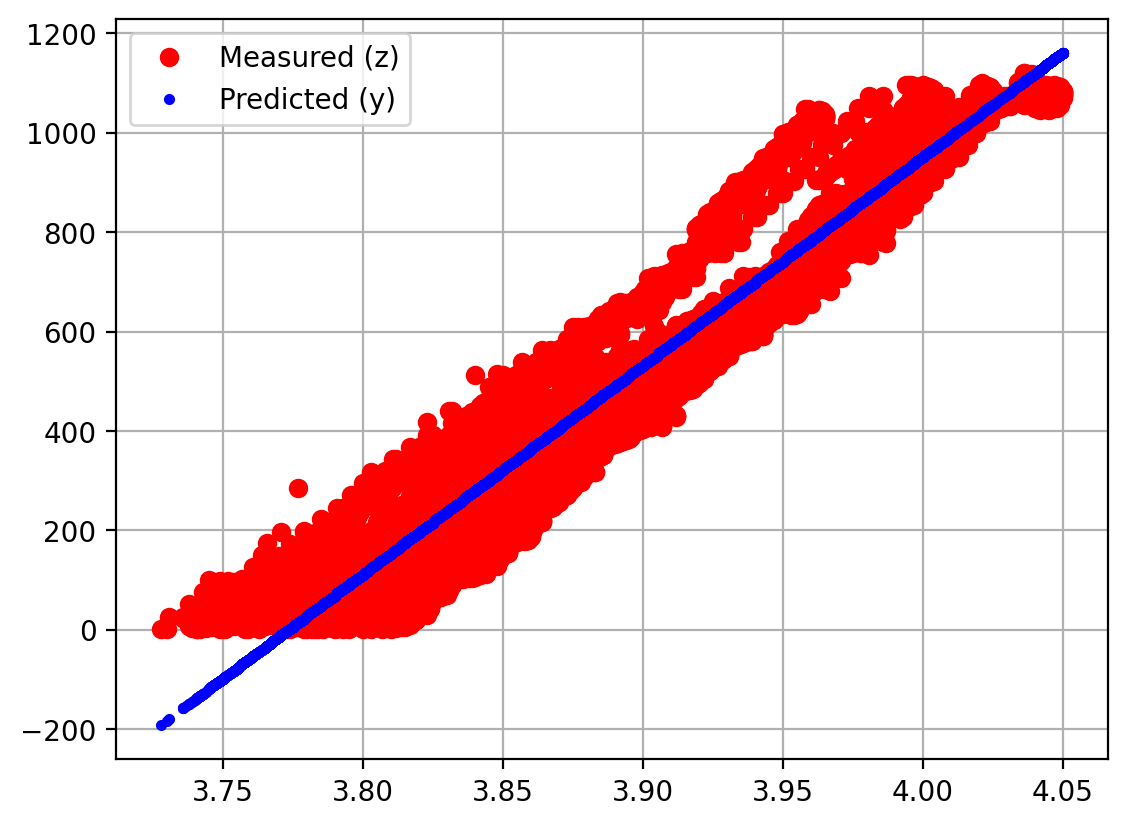

In [97]:

x = df['Max. Voltage Dischar. (V)'].values
z = df['RUL'].values
p1 = np.polyfit(x,z,1)
print('Slope, Intercept:' + str(p1))

plt.plot(x,z,'ro',label='Measured (z)')
plt.plot(x,np.polyval(p1,x),'b.',label='Predicted (y)')
plt.legend(); plt.grid()
plt.show()

Slope, Intercept: [  4180.38160241 -15775.05389377]


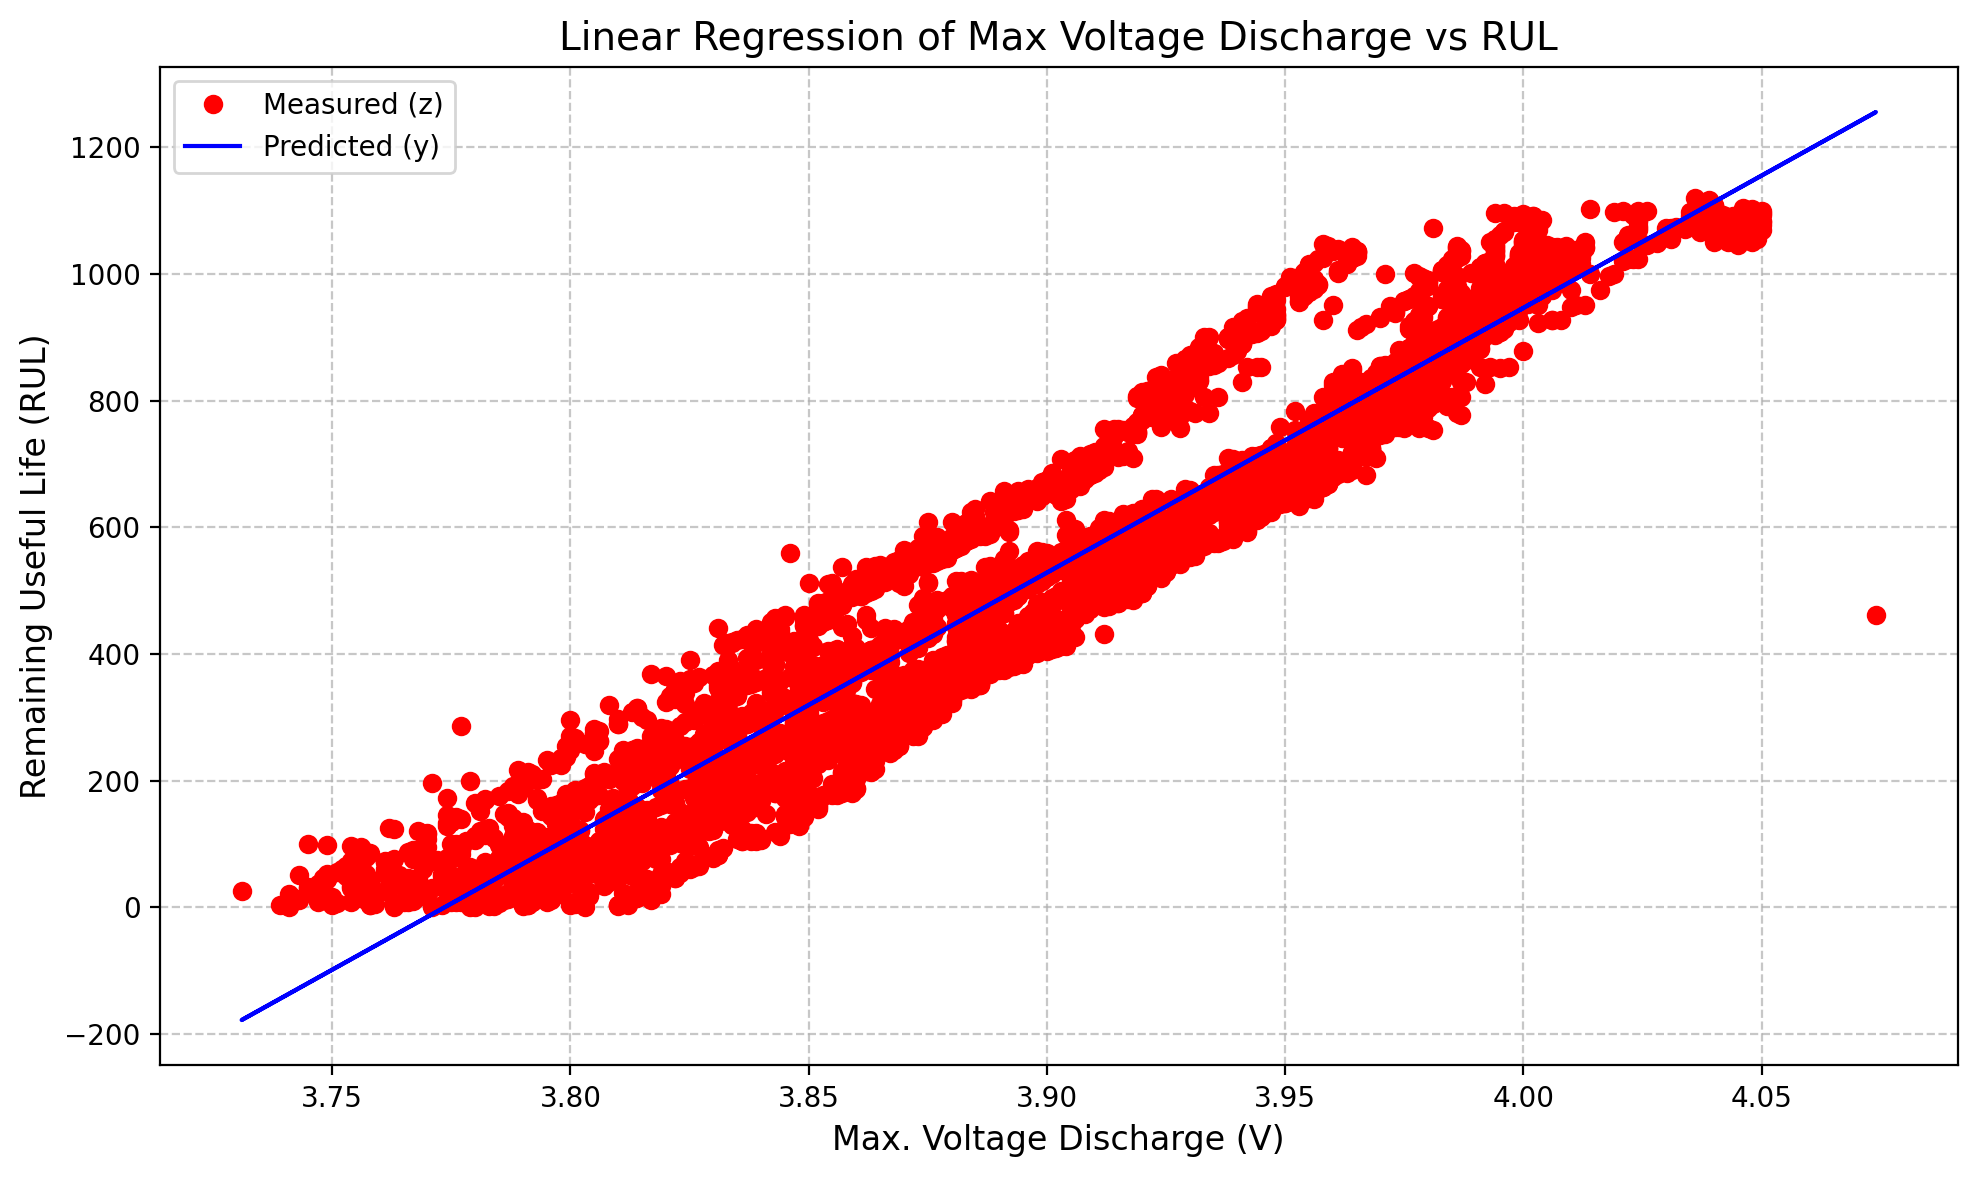

In [98]:
# using a fewer data points 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/Users/farid/Documents/GitHub/RUL_Local_Linear_Regression/EV Battery 5000.csv")

df = df[(df['Max. Voltage Dischar. (V)']<4.1) & (df['Max. Voltage Dischar. (V)']>3.7)]

x = df['Max. Voltage Dischar. (V)'].values  
z = df['RUL'].values 

p1 = np.polyfit(x, z, 1) 
print(f'Slope, Intercept: {p1}')  

plt.figure(figsize=(10, 6))  
plt.plot(x, z, 'ro', label='Measured (z)') 
plt.plot(x, np.polyval(p1, x), 'b-', label='Predicted (y)')  
plt.xlabel('Max. Voltage Discharge (V)', fontsize=12) 
plt.ylabel('Remaining Useful Life (RUL)', fontsize=12)  
plt.title('Linear Regression of Max Voltage Discharge vs RUL', fontsize=14)  
plt.legend(fontsize=10)  
plt.grid(True, linestyle='--', alpha=0.7) 
plt.tight_layout()
plt.show() 


In [ ]:
# Continuing from the documentation, in applying scaling
from sklearn.preprocessing import StandardScaler
s = StandardScaler()
ds = s.fit_transform(df)
type(ds)

ds = pd.DataFrame(ds,columns=df.columns)
# restore ID value
ds['Battery ID'] = df['Battery ID'].values
ds.head()

,Cycle_Index,Discharge Time (s),Decrement 3.6-3.4V (s),Max. Voltage Dischar. (V),Min. Voltage Charg. (V),Time at 4.15V (s),Time constant current (s),Charging time (s),RUL,Battery ID
0,-1.704337,1.789029,2.435850,1.828945,2.737570,-0.816968,-0.641335,-3.506653,1.712417,1
1,-1.701205,1.784390,2.435845,1.883706,-1.798789,1.818558,1.774628,1.583479,1.709285,1
2,-1.698074,1.777359,2.407937,1.883706,-1.790197,1.818556,1.769399,1.560957,1.706154,1
3,-1.694942,1.768032,2.380030,1.897397,-1.790197,1.812814,1.764147,1.477620,1.703023,1
4,-1.691810,1.762579,2.352117,1.911087,-1.790197,1.801360,1.758896,1.480683,1.699891,1


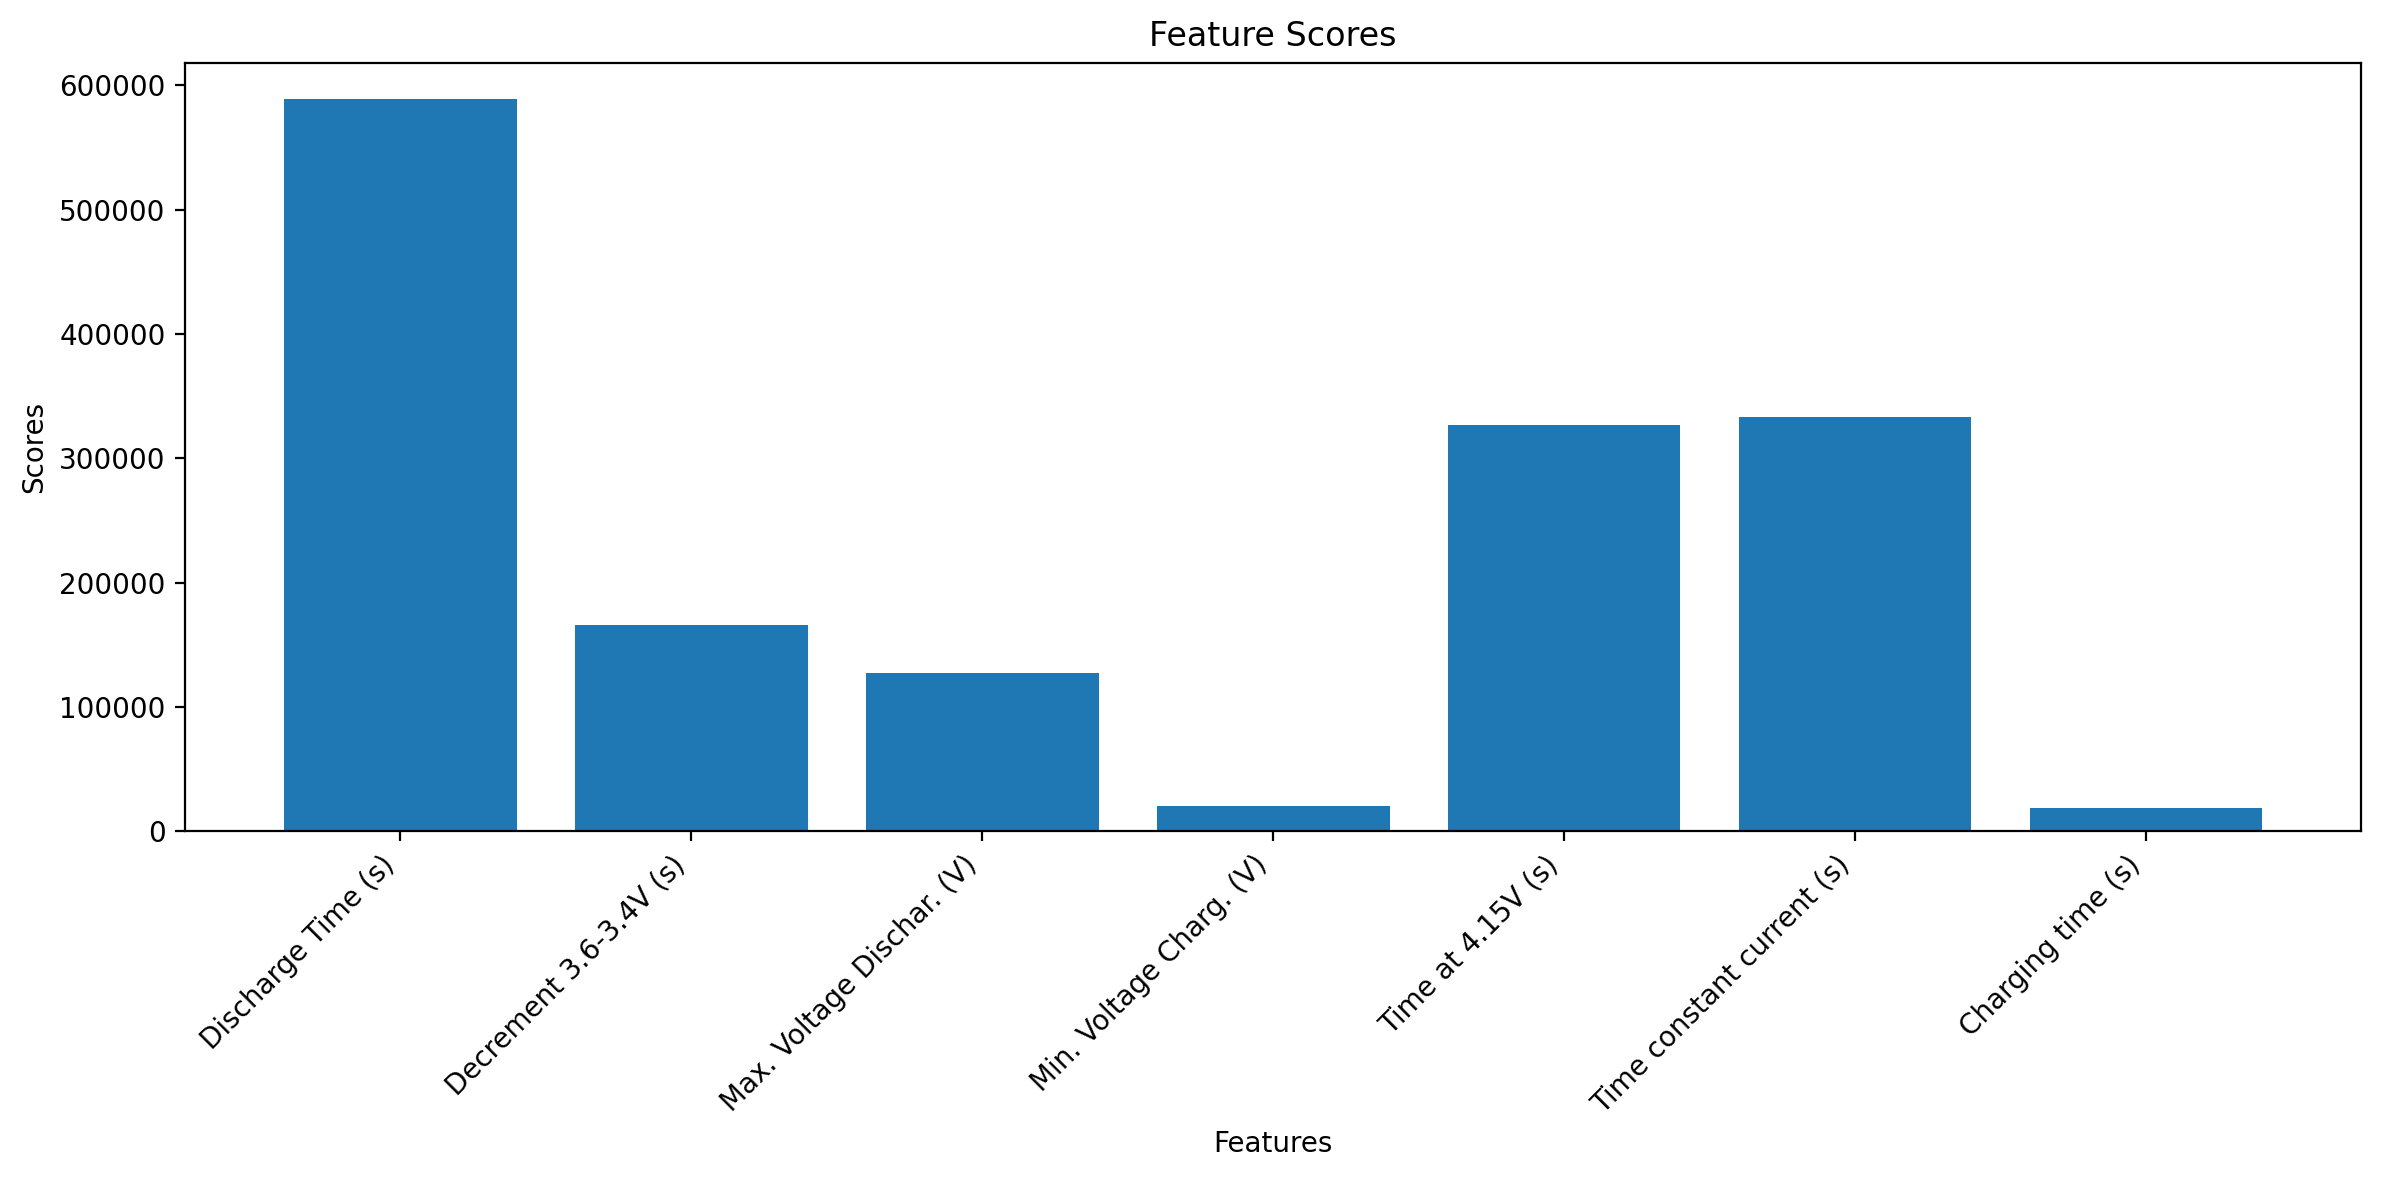

In [39]:
from sklearn.model_selection import train_test_split
train,test = train_test_split(ds, test_size=0.2, shuffle=True)

# train test is random, but we know that some of the data share several Battery ID so we have to ensure they do not mix
ids = ds['Battery ID'].unique()
total = len(ids)
split = int(np.floor(total*0.8))
train_ids = ids[0:split]
test_ids = ids[split:]

train = ds[ds['Battery ID'].isin(train_ids)]
test = ds[ds['Battery ID'].isin(test_ids)]

# select features
x_columns = list(train.columns[1:-2])
# select label (RUL)
z_column  = train.columns[-2]
x = train[x_columns]
z = train[z_column]

from sklearn.feature_selection import SelectKBest, f_regression
best = SelectKBest(score_func=f_regression, k='all')
fit = best.fit(x,z)

# to ensure the x label fit or legible
plt.figure(figsize=(12, 6))  
plt.bar(x=x.columns, height=fit.scores_)
plt.xticks(rotation=45, ha='right')  
plt.title('Feature Scores')
plt.xlabel('Features')
plt.ylabel('Scores')
plt.tight_layout()  
plt.show()

# remove lowest scoring features
x_columns = list(train.columns[1:-2])
x_columns.remove('Min. Voltage Charg. (V)')
x_columns.remove('Charging time (s)')

# build train set
xtrain = train[x_columns]
ytrain = train[z_column]

# build test set
xtest = test[x_columns]
ytest = test[z_column]

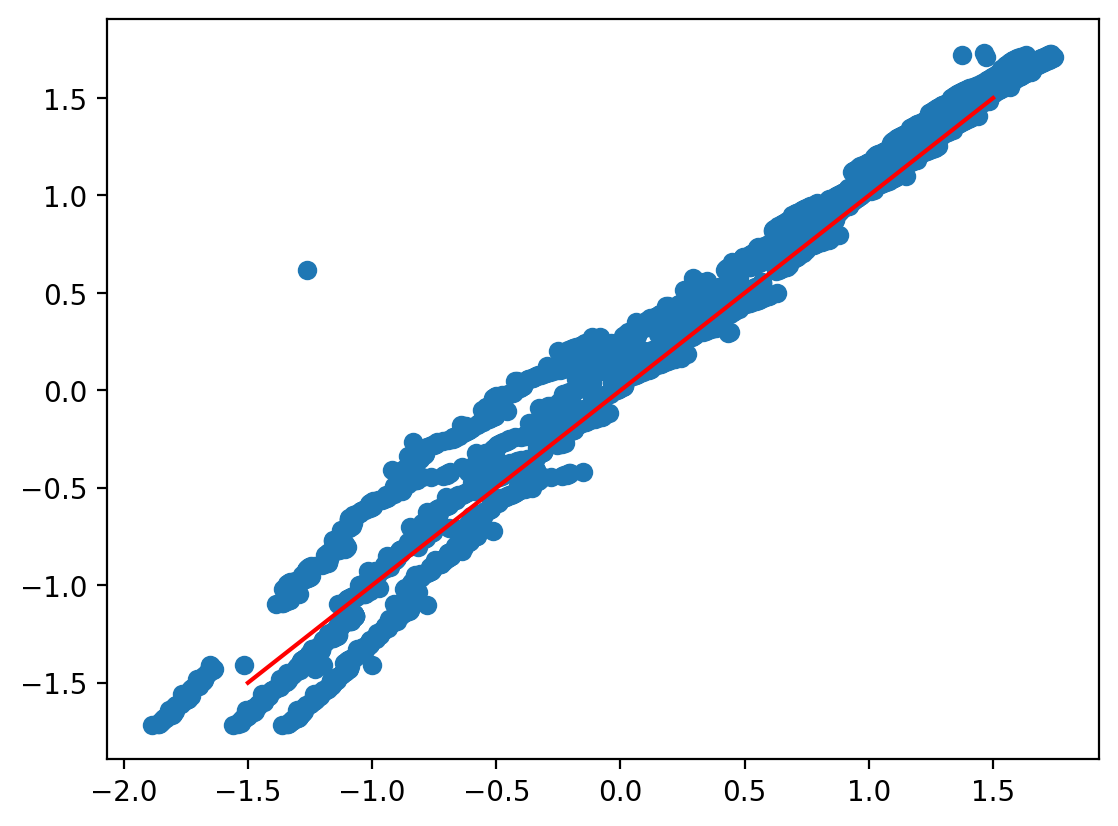

In [40]:
# predict with linear regression - possibly not used since we compare with a feature with NW estimator
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(xtrain, ytrain)
yp = lr.predict(xtest)
# show results with parity plot
plt.scatter(yp,ytest)
plt.plot([-1.5,1.5],[-1.5,1.5],'r-')

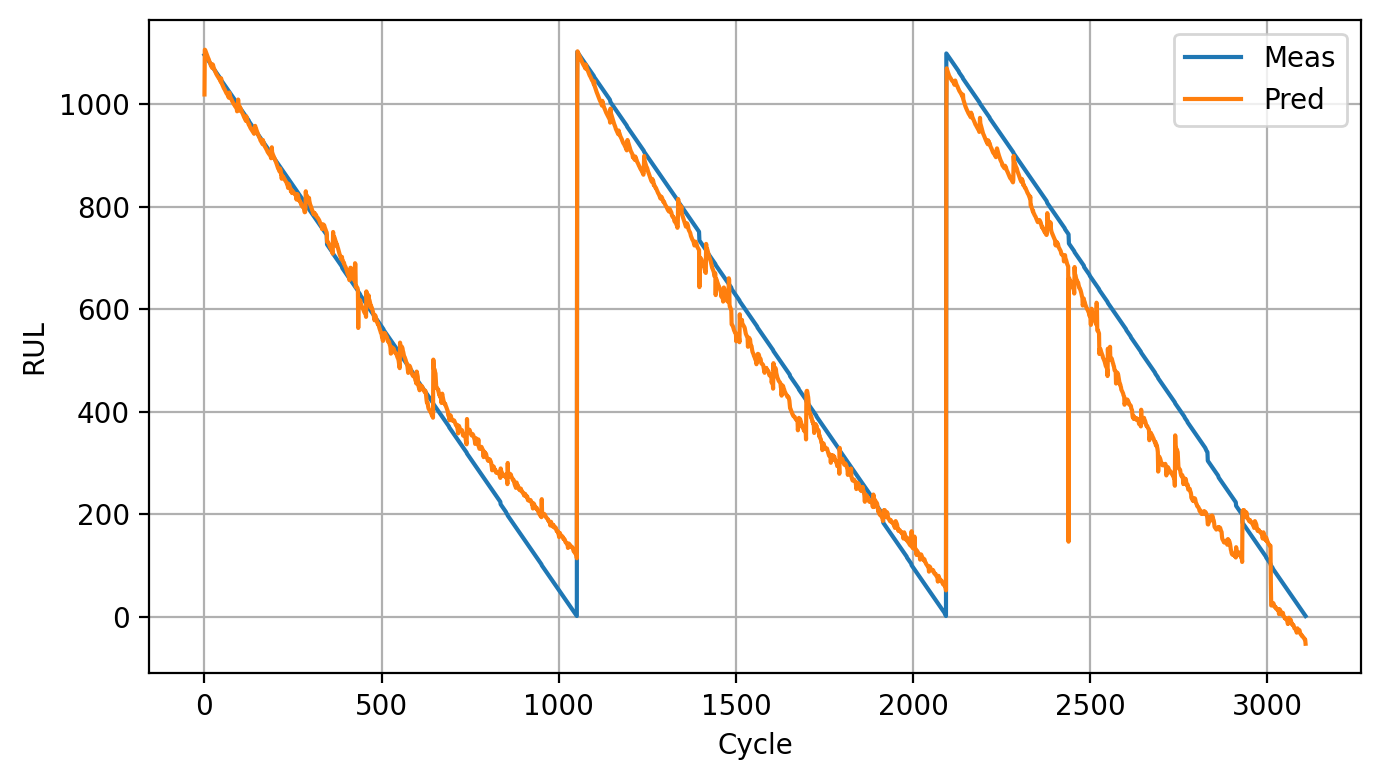

In [41]:
pred = test.copy()
pred['RUL'] = yp

df1 = s.inverse_transform(test)
dtest = pd.DataFrame(df1,columns=test.columns)
df2 = s.inverse_transform(pred)
dpred = pd.DataFrame(df2,columns=test.columns)

plt.figure(figsize=(7,4))
plt.plot(dtest.index,dtest['RUL'],label='Meas')
plt.plot(dpred.index,dpred['RUL'],label='Pred')
plt.legend(); plt.xlabel('Cycle');plt.ylabel('RUL')
plt.grid(); plt.tight_layout()

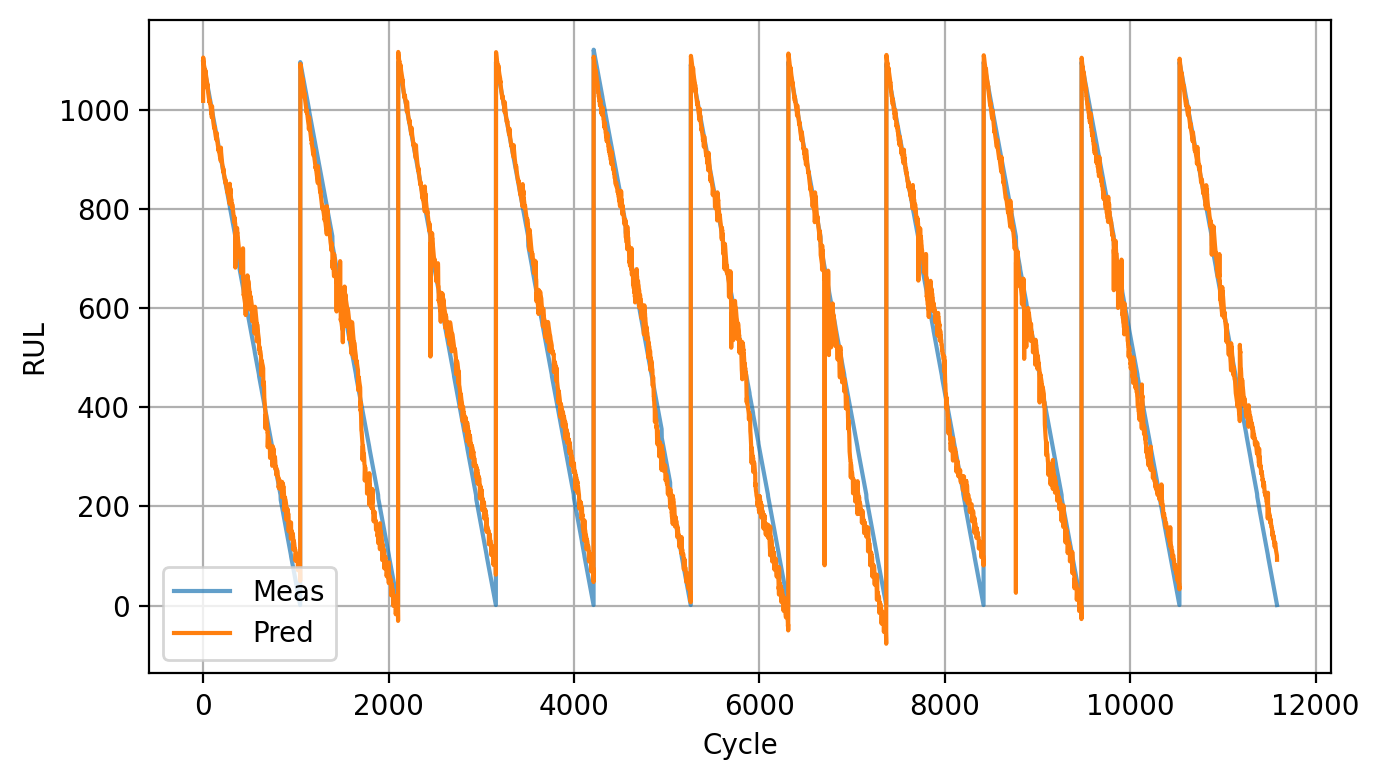

In [42]:
pred = train.copy()
yp = lr.predict(xtrain)
pred['RUL'] = yp

df1 = s.inverse_transform(train)
dtrain = pd.DataFrame(df1,columns=train.columns)
df2 = s.inverse_transform(pred)
dpred = pd.DataFrame(df2,columns=train.columns)

plt.figure(figsize=(7,4))
plt.plot(dtrain.index,dtrain['RUL'],label='Meas',alpha=0.7)
plt.plot(dpred.index,dpred['RUL'],label='Pred')
plt.legend(); plt.xlabel('Cycle');plt.ylabel('RUL')
plt.grid(); plt.tight_layout()

We adapt the NW Estimator and see the evolving value of the each bandwidth

984 samples


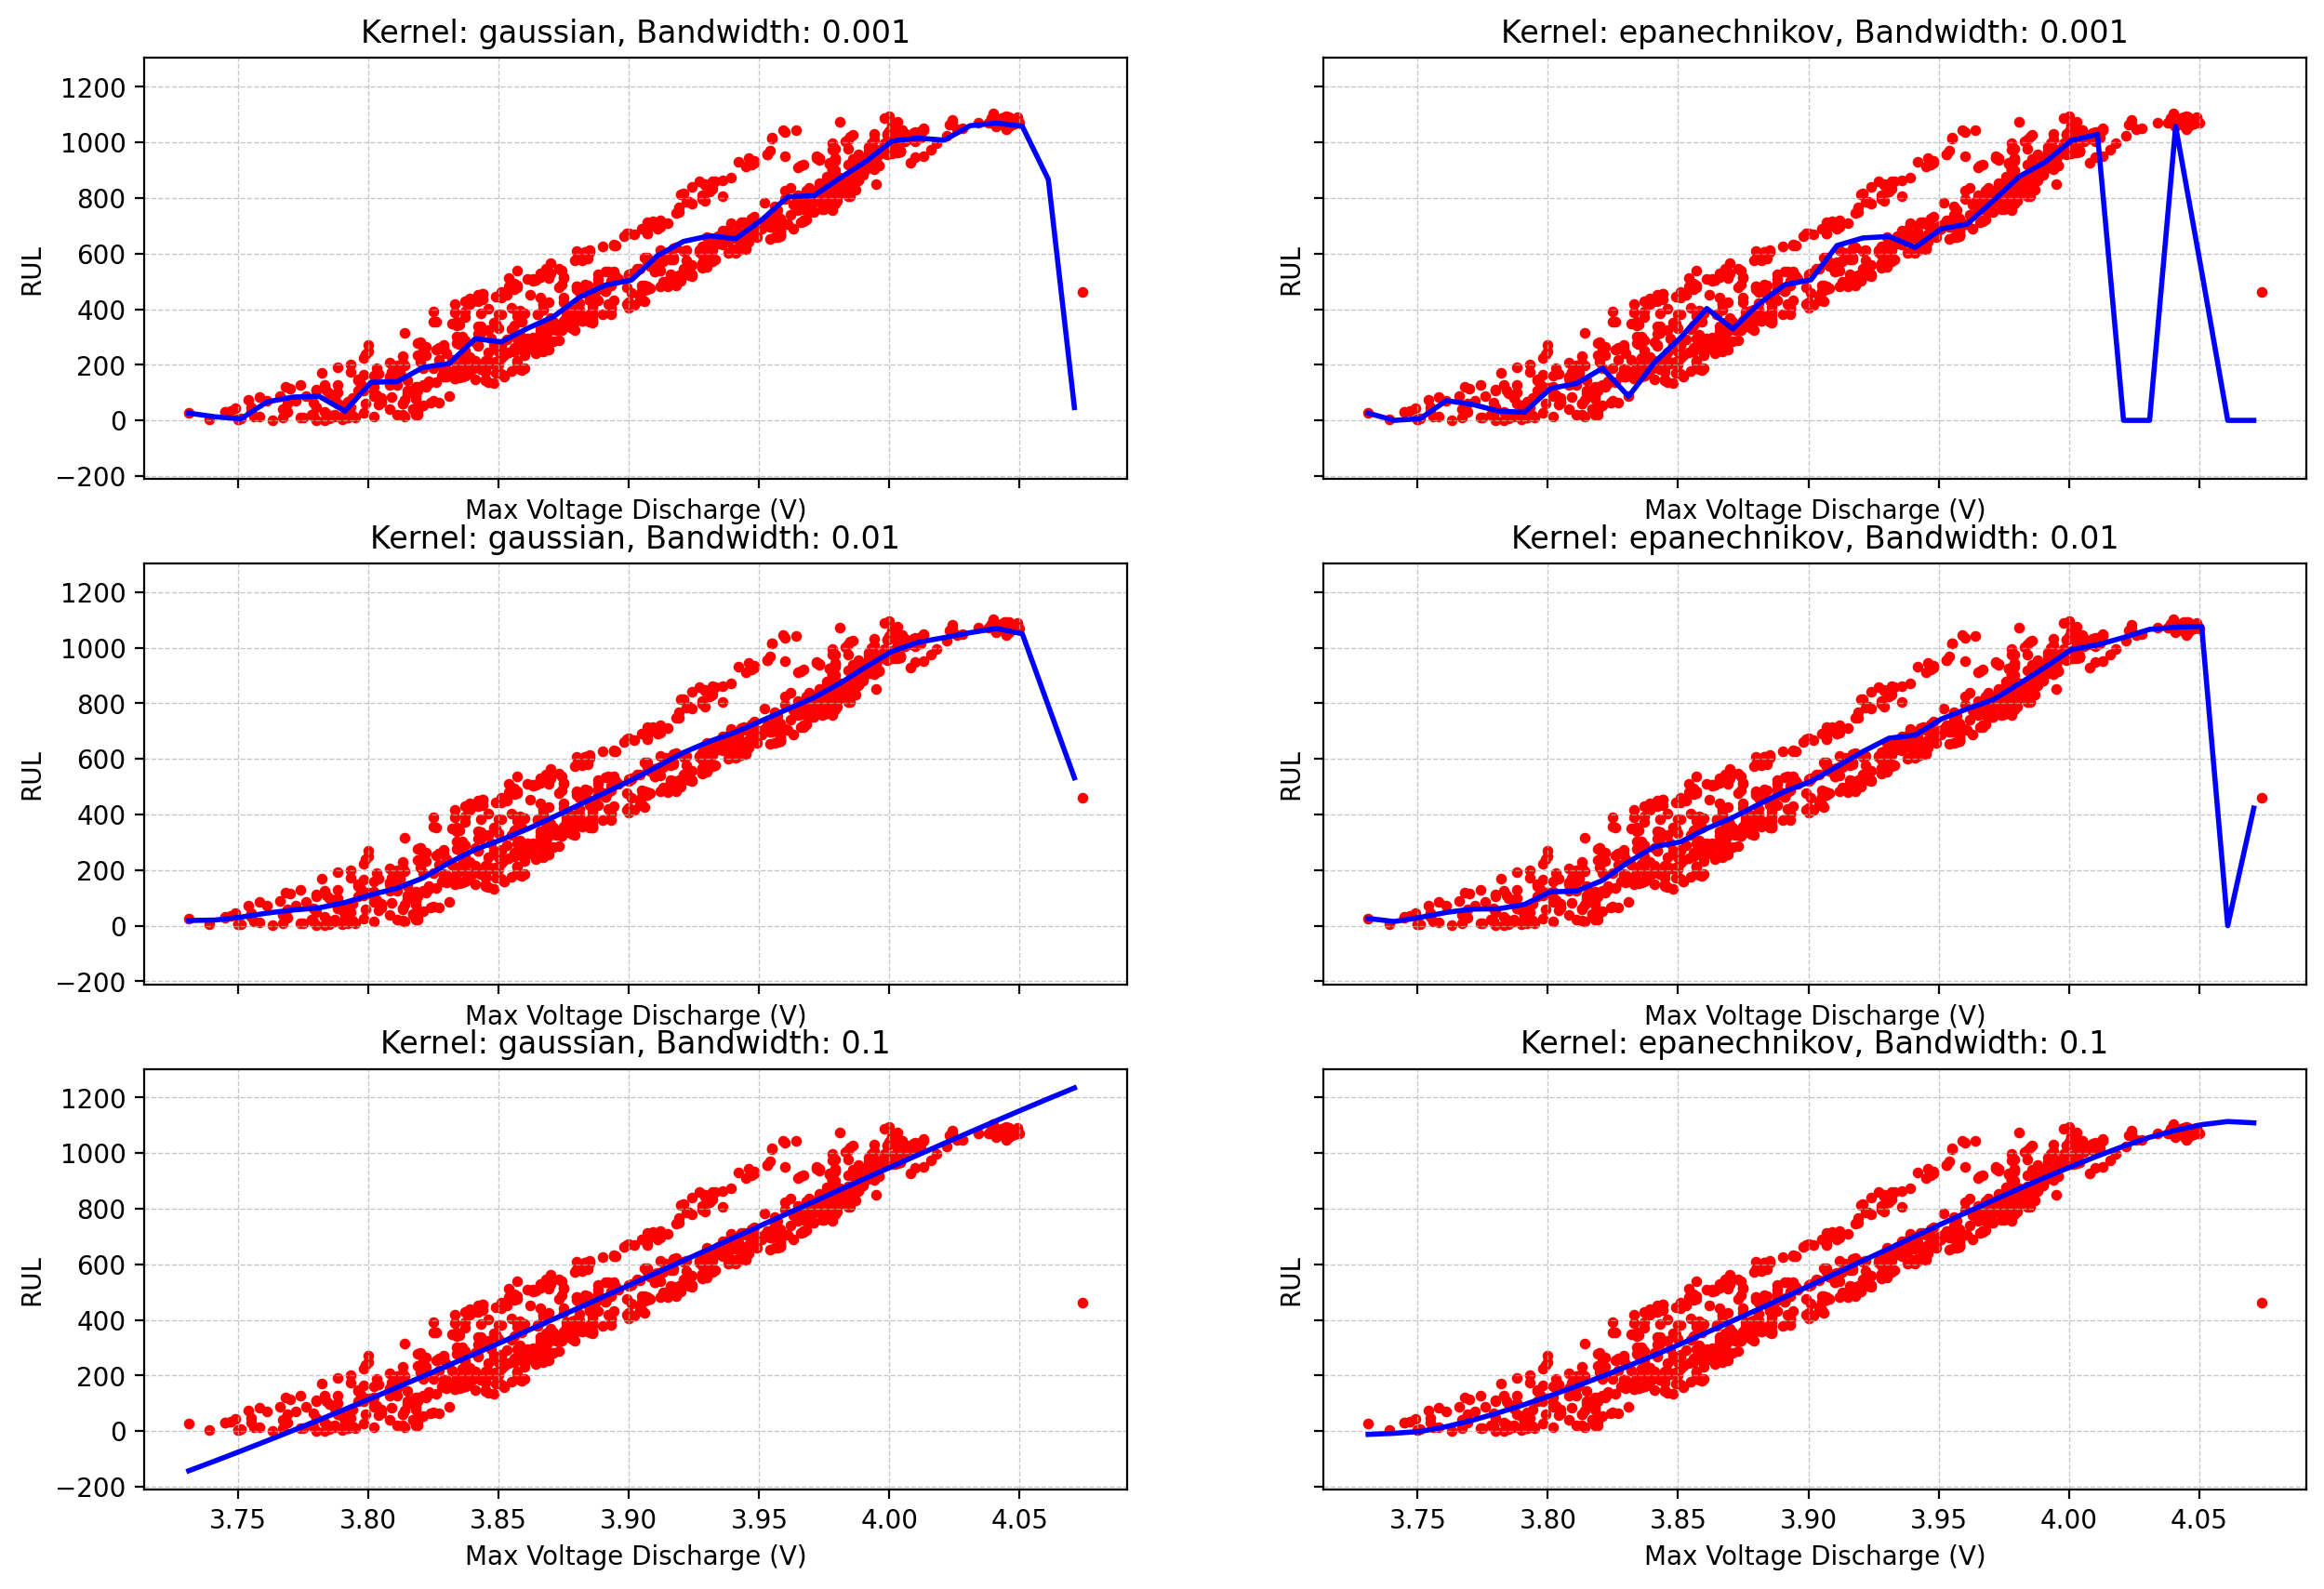

<Figure size 1000x600 with 0 Axes>

In [128]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import data_generation as dg
import estimation as es

plt.rcParams.update(plt.rcParamsDefault)

df = pd.read_csv("/Users/farid/Documents/GitHub/RUL_Local_Linear_Regression/EV Battery 1000.csv")
df = df[(df['Max. Voltage Dischar. (V)'] < 4.1) & (df['Max. Voltage Dischar. (V)'] > 3.7)]

max_vd = df["Max. Voltage Dischar. (V)"]
rul = df["RUL"]
n_train = len(df)
print(f"{n_train} samples")

data = dg.Data(n_train, n_test=0)
data.x_train = np.array(max_vd)
data.y_train = np.array(rul)

data.x_test = np.arange(max_vd.min(), max_vd.max(), step=0.01)
data.y_test = data.x_test

data.mu_train = data.y_train
data.eps_train = data.y_train

bandwidths = [0.001, 0.01, 0.1]
kernels = ["gaussian", "epanechnikov"]

fig, axes = plt.subplots(len(bandwidths), len(kernels), figsize=(15, 10), sharex=True, sharey=True)

for i, bandwidth in enumerate(bandwidths):
    for j, kernel in enumerate(kernels):
        
        lr = es.LocalRegression(kernel=kernel, bandwidth=bandwidth, degree=1, verbose=False)
        lr.fit(data)

        ax = axes[i, j]
        ax.scatter(data.x_train, data.y_train, s=10, color="red", label="Measured (z)")
        ax.plot(data.x_test, lr.fitted_test, color="blue", linewidth=2, label="Predicted (y)")
        ax.set_title(f"Kernel: {kernel}, Bandwidth: {bandwidth}")
        ax.set_xlabel("Max Voltage Discharge (V)")
        ax.set_ylabel("RUL")
        ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.7)


plt.figure(figsize=(10, 6))
plt.tight_layout()
plt.show()


984 samples


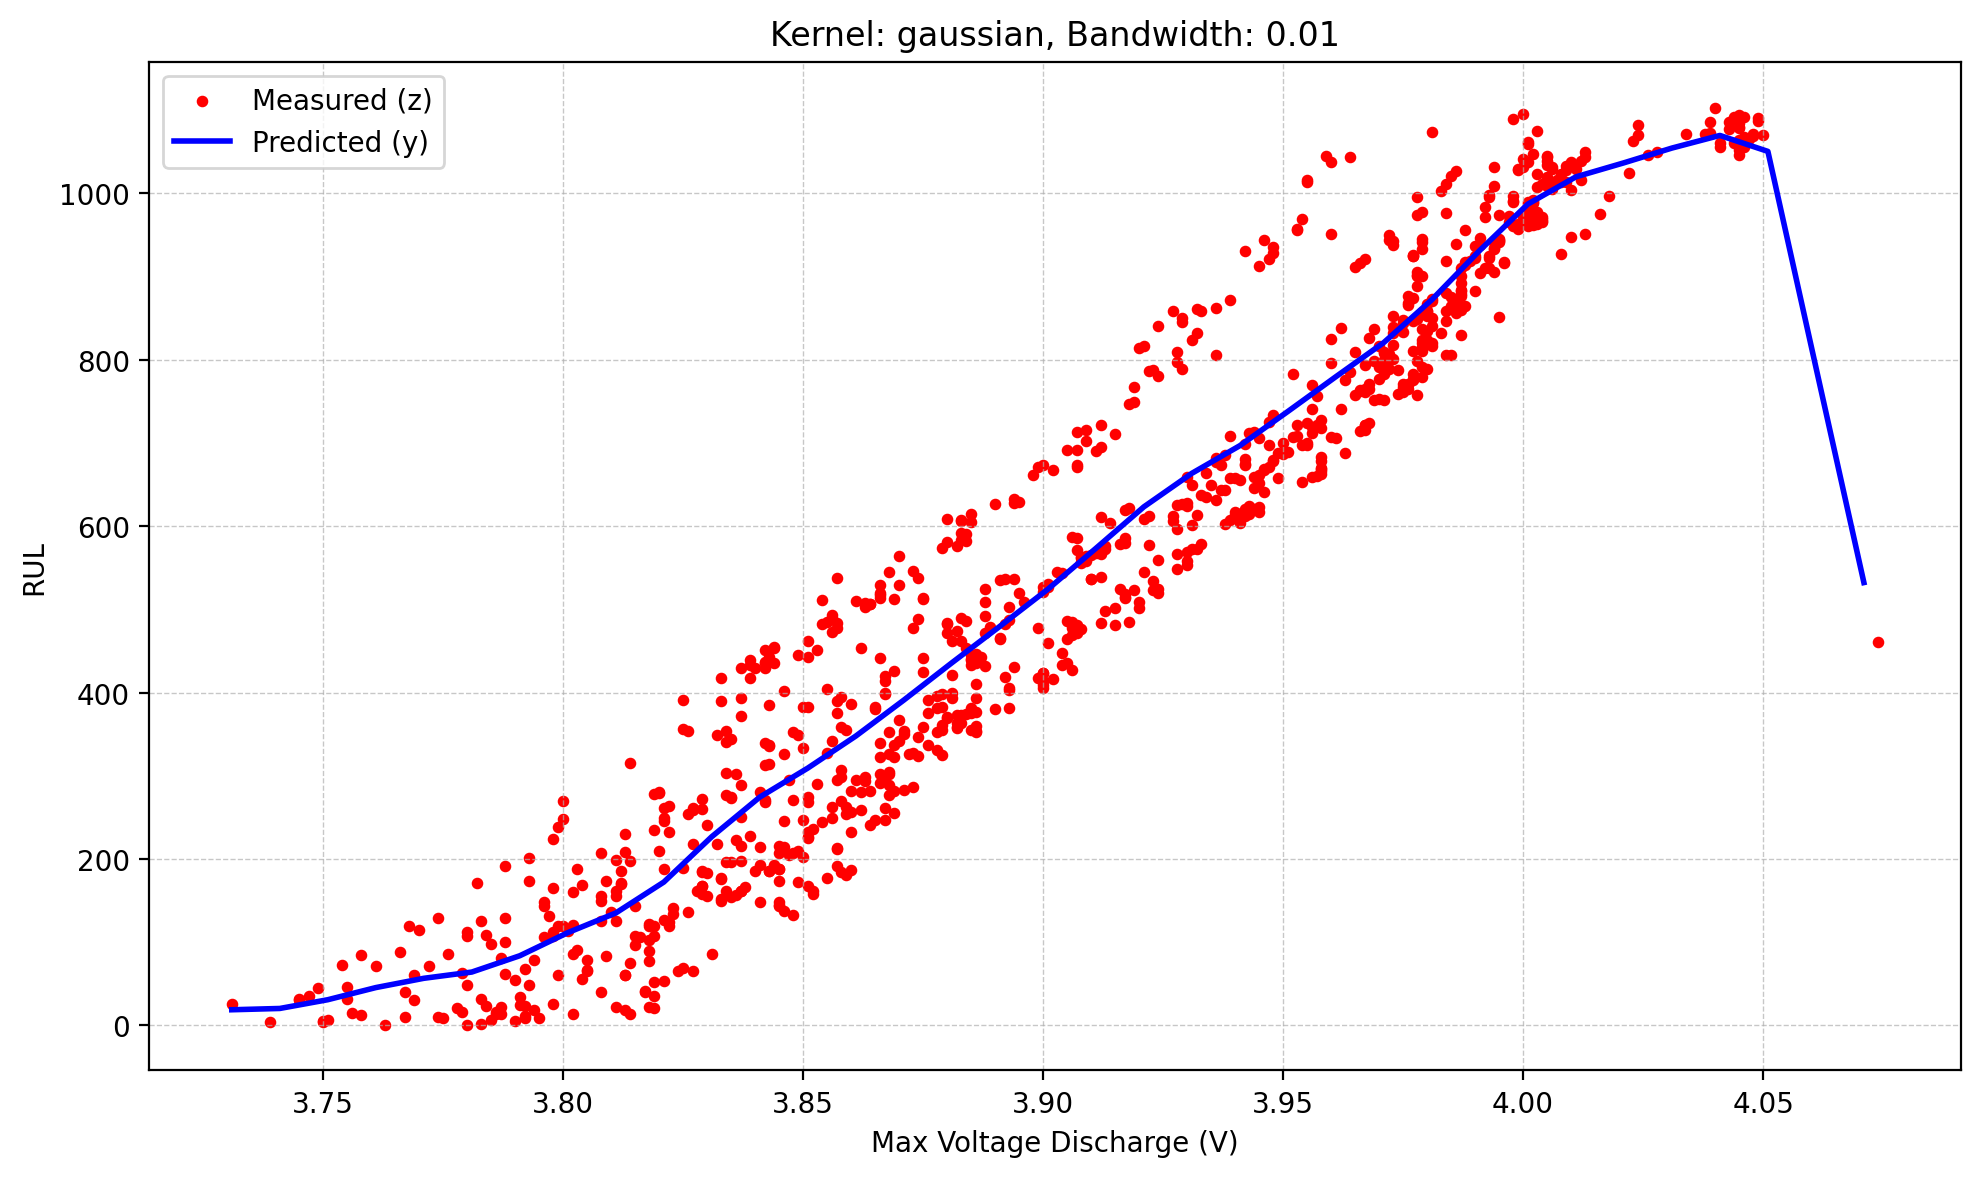

In [127]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import data_generation as dg
import estimation as es

plt.rcParams.update(plt.rcParamsDefault)

df = pd.read_csv("/Users/farid/Documents/GitHub/RUL_Local_Linear_Regression/EV Battery 1000.csv")
df = df[(df['Max. Voltage Dischar. (V)'] < 4.1) & (df['Max. Voltage Dischar. (V)'] > 3.7)]

max_vd = df["Max. Voltage Dischar. (V)"]
rul = df["RUL"]
n_train = len(df)
print(f"{n_train} samples")

data = dg.Data(n_train, n_test=0)
data.x_train = np.array(max_vd)
data.y_train = np.array(rul)

data.x_test = np.arange(max_vd.min(), max_vd.max(), step=0.01)
data.y_test = data.x_test

data.mu_train = data.y_train
data.eps_train = data.y_train

bandwidth = 0.01
kernel = "gaussian"

lr = es.LocalRegression(kernel=kernel, bandwidth=bandwidth, degree=1, verbose=False)
lr.fit(data)

plt.figure(figsize=(10, 6))
plt.scatter(data.x_train, data.y_train, s=10, color="red", label="Measured (z)")
plt.plot(data.x_test, lr.fitted_test, color="blue", linewidth=2, label="Predicted (y)")
plt.title(f"Kernel: {kernel}, Bandwidth: {bandwidth}")
plt.xlabel("Max Voltage Discharge (V)")
plt.ylabel("RUL")
plt.grid(True, linestyle="--", linewidth=0.5, alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()
